# AnomalyDINO with leave-one-out threshold, final model on the anomalib Engine

Model: anomalib `AnomalyDINO` with its defaults (DINOv2 ViT-S/14, last block, 1-NN cosine distance), plus:

1. **Resize keeps the crop's aspect ratio.** Crops are 1381x470 (2.94:1); the default 252x252 squashes the pill ~3x. Here: 252 x 742 (18 x 53 patches of 14 px).
2. **Threshold from good images only, by leave-one-out (LOO).** For each good image: memory bank from the other 11, score the left-out one. Image threshold = highest LOO image score x 1.2, pixel threshold = highest LOO pixel value x 1.1 (margin for good pills not seen yet). LOO is our own loop around the model, not part of anomalib.
3. **Final model on the `Engine`**: bank from all 12 good images, the LOO thresholds go into the `PostProcessor`, so `engine.predict` returns labels and masks with them, writes the 3-panel images to `results/`, and `engine.export` would carry them.

RAM: `num_workers=0` (the default 8 dataloader workers each load torch), LOO reads images per batch.

In [1]:
import gc
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from anomalib.data import Folder
from anomalib.engine import Engine
from anomalib.models import AnomalyDINO
from anomalib.post_processing import PostProcessor

CROPS = Path('data/crops')
SIZE = (252, 742)   # (H, W): multiples of 14, ratio 2.94 like the 1381x470 crops
BATCH = 4
DEVICE = 'cuda'
IMAGE_MARGIN = 1.2  # image threshold = max LOO image score x this
PIXEL_MARGIN = 1.1  # pixel threshold = max LOO pixel value x this
PRE = AnomalyDINO.configure_pre_processor(image_size=SIZE)  # resize + ImageNet normalize, shared by LOO and Engine

by_num = lambda p: int(p.stem)
good = sorted((CROPS / 'good').glob('*.png'), key=by_num)
defect = sorted((CROPS / 'defect').glob('*.png'), key=by_num)
print(len(good), 'good,', len(defect), 'defect')

/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


12 good, 14 defect


/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


## Leave-one-out on the good images

Uses the torch model inside `AnomalyDINO` (`.model`) directly: building 12 banks through the Engine would need 12 temporary folders.

In [2]:
def to_tensor(paths):
    """Read a few crops (RGB, [0, 1]) and apply the model's pre-processing, on the GPU."""
    imgs = [cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB) for p in paths]
    x = torch.from_numpy(np.stack(imgs)).to(DEVICE).permute(0, 3, 1, 2).float() / 255
    return PRE.transform(x)


def batches(paths):
    for i in range(0, len(paths), BATCH):
        yield paths[i:i + BATCH]


@torch.no_grad()
def loo_one(bank_paths, query):
    """Bank from bank_paths, then raw score and anomaly map of the query image."""
    model = AnomalyDINO().model.to(DEVICE)
    model.train()  # training mode = collect patch features into the bank
    for b in batches(bank_paths):
        model(to_tensor(b))
    model.fit()
    out = model.eval()(to_tensor([query]))
    score, amap = out.pred_score[0, 0].item(), out.anomaly_map[0, 0].cpu().numpy()
    del model
    gc.collect(); torch.cuda.empty_cache()
    return score, amap


loo_score, loo_map = [], []
for i, p in enumerate(good):
    s, m = loo_one(good[:i] + good[i + 1:], p)
    loo_score.append(s); loo_map.append(m)
    print(f'good/{p.stem}: LOO score {s:.4f}, max pixel {m.max():.4f}')
loo_score = np.array(loo_score); loo_map = np.stack(loo_map)

IMAGE_THR = float(loo_score.max() * IMAGE_MARGIN)
PIXEL_THR = float(loo_map.max() * PIXEL_MARGIN)
print(f'image threshold {IMAGE_THR:.4f}, pixel threshold {PIXEL_THR:.4f}')

good/1: LOO score 0.1667, max pixel 0.1821
good/2: LOO score 0.1782, max pixel 0.1985
good/3: LOO score 0.2018, max pixel 0.2287
good/4: LOO score 0.1896, max pixel 0.2285
good/5: LOO score 0.2072, max pixel 0.2189
good/6: LOO score 0.1979, max pixel 0.2087
good/7: LOO score 0.1684, max pixel 0.1913
good/8: LOO score 0.2197, max pixel 0.2294
good/9: LOO score 0.1506, max pixel 0.1592
good/10: LOO score 0.1464, max pixel 0.1565
good/11: LOO score 0.1995, max pixel 0.2239
good/12: LOO score 0.2101, max pixel 0.2409
image threshold 0.2636, pixel threshold 0.2650


## Final model on the Engine

`PostProcessor` always labels `value > 1 - sensitivity`. With normalization off the values are raw distances, so `sensitivity = 1 - threshold` makes it compare against the LOO threshold directly.
`test_split_mode='none'`: otherwise `Folder` moves 20% of the good images out of the bank into a test split.

In [3]:
post = PostProcessor(
    enable_normalization=False,
    image_sensitivity=1 - IMAGE_THR,
    pixel_sensitivity=1 - PIXEL_THR,
)
model = AnomalyDINO(pre_processor=PRE, post_processor=post)
datamodule = Folder(
    name='pill', root=CROPS, normal_dir='good',
    test_split_mode='none', val_split_mode='none',
    train_batch_size=BATCH, eval_batch_size=BATCH, num_workers=0,
)
datamodule.setup()
engine = Engine()
# train loader only: no validation needed (thresholds come from LOO), the bank is built at the end of the epoch
engine.fit(model=model, train_dataloaders=datamodule.train_dataloader())
print('memory bank:', tuple(model.model.memory_bank.shape), '(12 images x 18 x 53 patches expected)')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
You are using a CUDA device ('NVIDIA GeForce RTX 3050 Ti Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/lightning/py

┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor     │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor    │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator        │      0 │ train │     0 │
│ 3 │ model          │ AnomalyDINOModel │ 22.1 M │ train │     0 │
└───┴────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 22.1 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 22.1 M                                                                                               
Total estimated model params size (MB): 88.225                                                                     
Modules in train mode: 295                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
`Trainer.fit` stopped: `max_epochs=1` reached.


memory bank: (11448, 384) (12 images x 18 x 53 patches expected)


In [4]:
predictions = engine.predict(model=model, data_path=CROPS / 'defect')
res = {}
for batch in predictions:
    for path, score, label, amap, mask in zip(batch.image_path, batch.pred_score, batch.pred_label, batch.anomaly_map, batch.pred_mask):
        res[Path(path).stem] = dict(score=float(score), label=bool(label), amap=amap.squeeze().cpu().numpy(), mask=mask.squeeze().cpu().numpy())

for p in defect:
    r = res[p.stem]
    print(f"defect/{p.stem:>2}: score {r['score']:.4f} {'DEFECT' if r['label'] else 'good  '}  mask {r['mask'].mean() * 100:5.1f}% of crop")
print(f"{sum(r['label'] for r in res.values())}/{len(defect)} defect crops flagged")

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ducduy/pill_defect/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


defect/ 1: score 0.3867 DEFECT  mask   1.8% of crop
defect/ 2: score 0.3871 DEFECT  mask   1.9% of crop
defect/ 3: score 0.6266 DEFECT  mask  10.0% of crop
defect/ 4: score 0.6490 DEFECT  mask  11.1% of crop
defect/ 5: score 0.5766 DEFECT  mask  14.1% of crop
defect/ 6: score 0.5741 DEFECT  mask  13.8% of crop
defect/ 7: score 0.4997 DEFECT  mask   3.5% of crop
defect/ 8: score 0.4911 DEFECT  mask   4.8% of crop
defect/ 9: score 0.5136 DEFECT  mask   3.3% of crop
defect/10: score 0.5181 DEFECT  mask   3.2% of crop
defect/11: score 0.7136 DEFECT  mask   6.9% of crop
defect/12: score 0.6946 DEFECT  mask   6.9% of crop
defect/13: score 0.5759 DEFECT  mask  12.6% of crop
defect/14: score 0.4412 DEFECT  mask   4.2% of crop
14/14 defect crops flagged


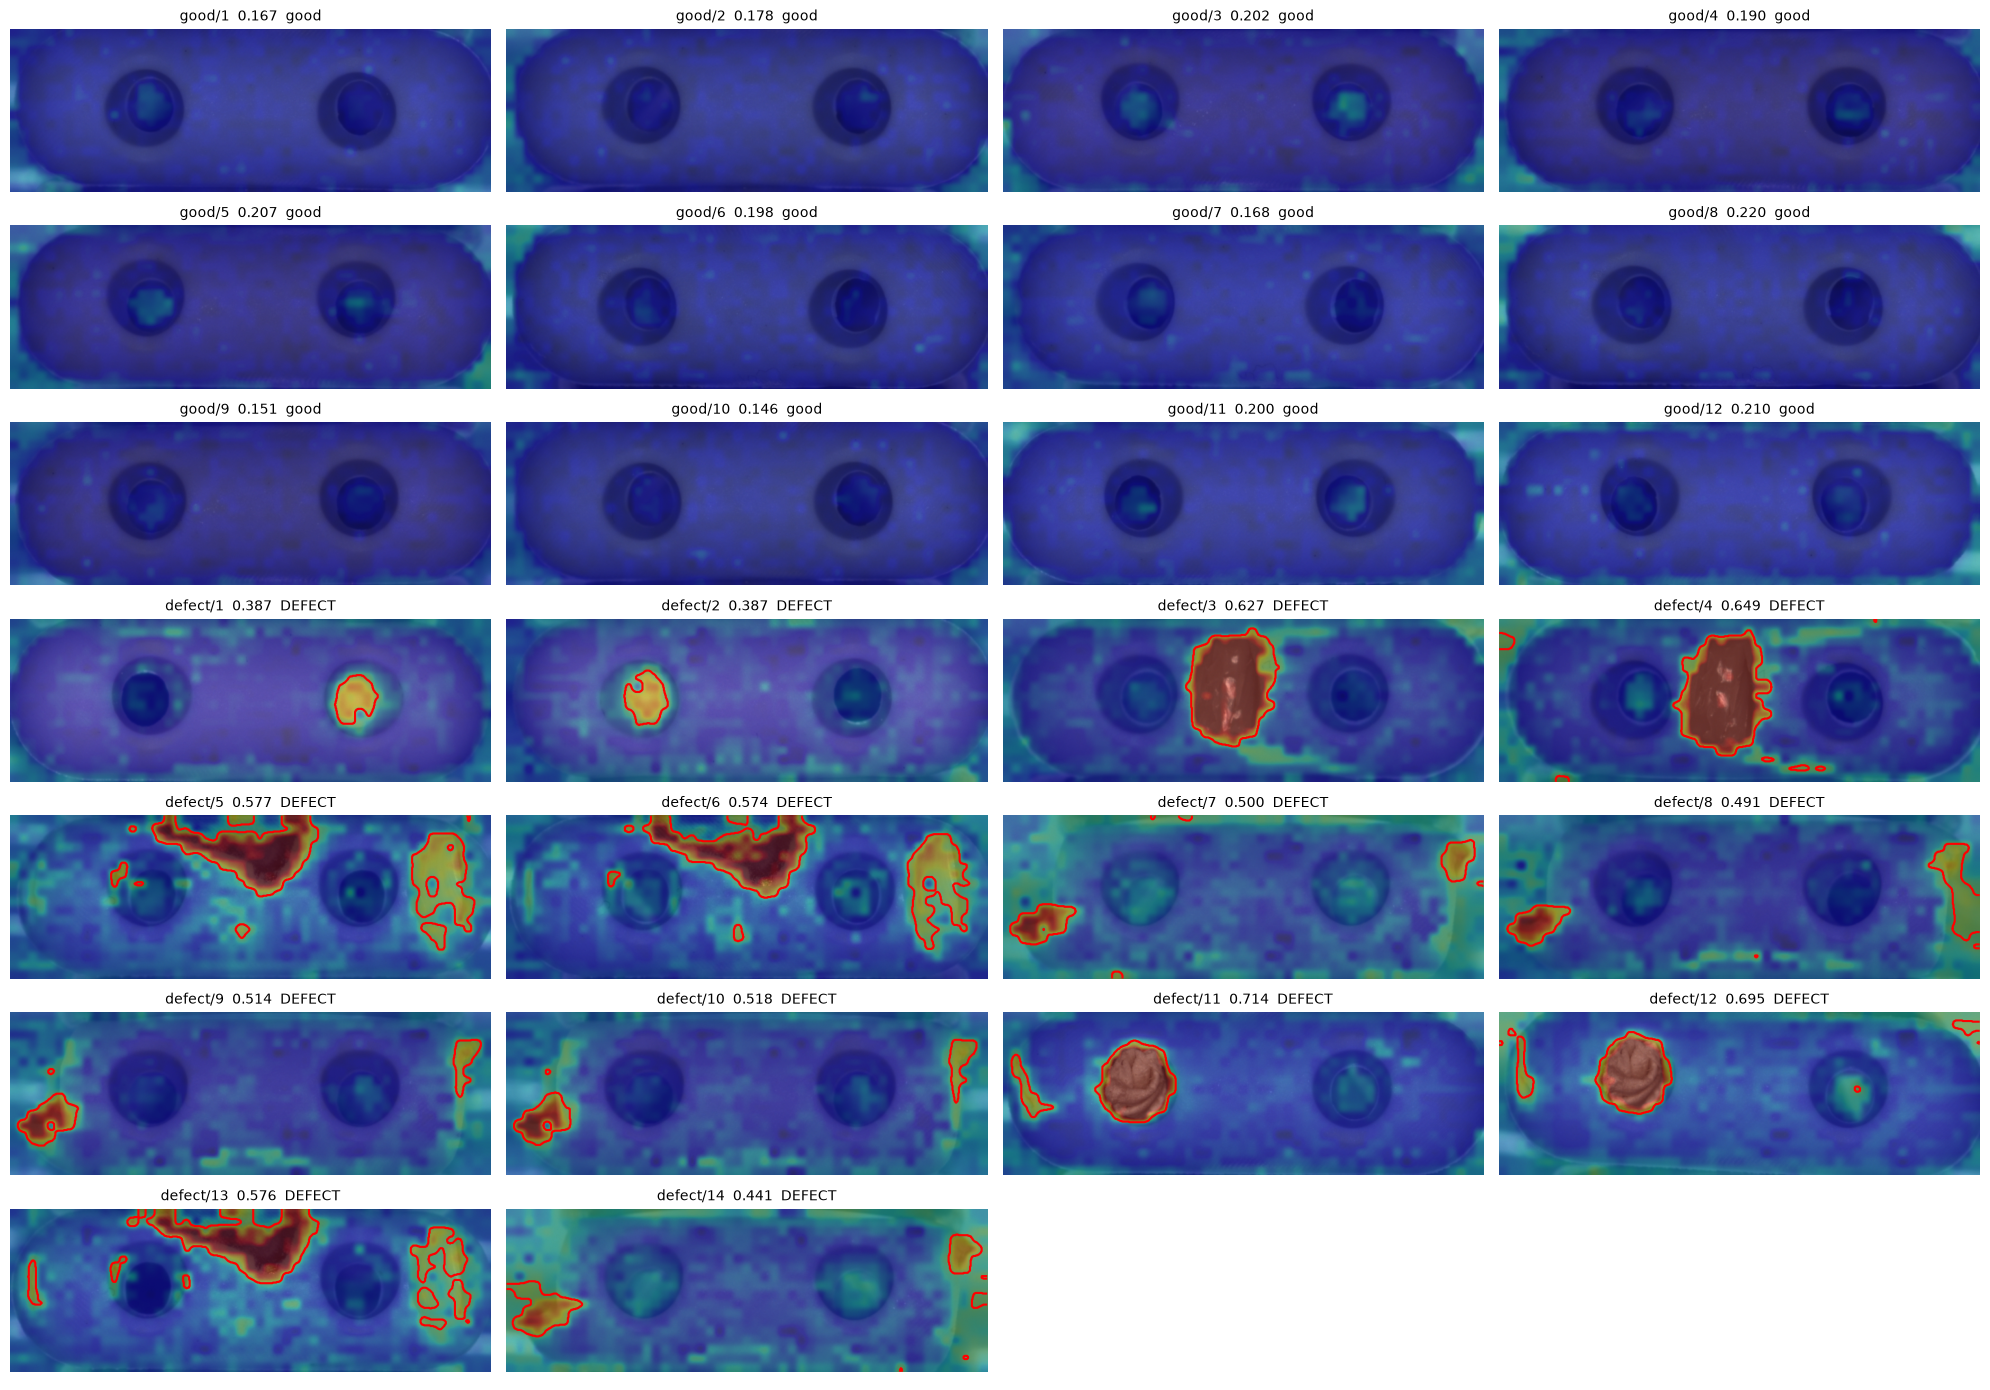

In [5]:
# good images with their LOO maps (the honest ones), defect images from the Engine
rows = [(f'good/{p.stem}', p, s, m, m > PIXEL_THR, s > IMAGE_THR) for p, s, m in zip(good, loo_score, loo_map)]
rows += [(f'defect/{p.stem}', p, res[p.stem]['score'], res[p.stem]['amap'], res[p.stem]['mask'], res[p.stem]['label']) for p in defect]

cols = 4
fig, ax = plt.subplots(-(-len(rows) // cols), cols, figsize=(cols * 5, -(-len(rows) // cols) * 2))
for a in ax.flat:
    a.axis('off')
for a, (name, p, s, m, mask, label) in zip(ax.flat, rows):
    img = cv2.resize(cv2.imread(str(p))[..., ::-1], SIZE[::-1], interpolation=cv2.INTER_AREA)
    a.imshow(img)
    a.imshow(m, cmap='jet', alpha=0.4, vmin=0, vmax=2 * PIXEL_THR)  # PIXEL_THR sits in the middle of the colour scale
    a.contour(mask, levels=[0.5], colors='red', linewidths=1.5)
    a.set_title(f"{name}  {s:.3f}  {'DEFECT' if label else 'good'}", fontsize=10)
plt.tight_layout()
Path('outputs').mkdir(exist_ok=True)
plt.savefig('outputs/anomaly_dino_loo.png', dpi=80)